In [83]:
import numpy as np
import pandas as pd
import os

### I.Importations des 10 fichiers brutes


In [84]:
# Chemins des dossiers
dossier_brut = "../02_DATA_BRUTE"
dossier_nettoye = "../04_PYTHON/DATA_NETTOYEE"

# Créer le dossier de sortie s'il n'existe pas
os.makedirs(dossier_nettoye, exist_ok=True)

# Liste des fichiers CSV
fichiers = os.listdir(dossier_brut)

print(fichiers)

['.gitkeep', 'ACHATS_BRUT.csv', 'CLIENTS_BRUT.csv', 'COMMERCIAUX_BRUT.csv', 'DEPENSES_BRUT.csv', 'FOURNISSEURS_BRUT.csv', 'LIVRAISONS_BRUT.csv', 'MAGASINS_BRUT.csv', 'PRODUITS_BRUT.csv', 'STOCKS_BRUT.csv', 'VENTES_BRUT.csv']


### II. Traitement (types, normalisation, valeurs incoherentes, valeur manquante.)


 1.Table VENTES

In [85]:
ventes = pd.read_csv(os.path.join(dossier_brut, "VENTES_BRUT.csv"))
ventes.head(2)

,id_vente,date_vente,id_client,id_produit,id_magasin,id_commercial,quantite,prix_unitaire_fcfa,remise_pct,cout_unitaire_fcfa,mode_paiement,statut_vente,canal_vente
0,VTE000001,2025-05-14,CLI01275,PRD0090,MAG002,COM017,1,14750.0,0.0,12125,Espèces,Validée,En ligne
1,VTE000002,2025-02-09,CLI02526,PRD0017,MAG008,COM020,2,12950.0,0.0,10376,Carte bancaire,Validée,Magasin


Variables categorielle / remplacement des mode de paiement vide par Inconnu

In [86]:
ventes["statut_vente"] =  (
    ventes["statut_vente"]
    .astype("string")
    .str.strip()
    .str.title()
)
mapping_statut = {
    'Validee': 'Validée',
    'Annulee': 'Annulée',
    'Retournee': 'Retournée'

}
ventes["statut_vente"] = ventes["statut_vente"].replace(mapping_statut)

ventes["statut_vente"] = ventes["statut_vente"].replace(
    ["nan", "inconnu", "none", ""], np.nan
)

ventes["mode_paiement"] = ventes["mode_paiement"].fillna("Inconnu")

ventes["statut_vente"].unique()

    

<StringArray>
['Validée', 'Annulée', 'En Attente', 'Retournée']
Length: 4, dtype: string

Variables entieres / les quantites negatives qui n'ont pas le statut de vente a 'Retournée' sont remplacees par le vide.

In [87]:
ventes["quantite"] = pd.to_numeric(
    ventes["quantite"], errors="coerce"
).astype("Int64")

condition = (ventes["quantite"] < 0) & (ventes["statut_vente"] != "Retournée")
ventes.loc[condition, "quantite"] = ventes.loc[condition, "quantite"].abs()

ventes["quantite"] = ventes["quantite"].astype("Int64")

Variables flottantes / les prix_unitaire_fcfa negative sont remplace par la valeur absolu et ceux qui sont manquants sont remplaces par le prix deja renseigne du meme produit.

In [88]:

columns_float = [
    "prix_unitaire_fcfa",
    "remise_pct",
    "cout_unitaire_fcfa",
]

for col in columns_float:
    ventes[col] = pd.to_numeric(ventes[col], errors="coerce", downcast="float")

# 1. Remplacer les prix unitaires négatifs par leur valeur absolue
ventes.loc[
    ventes["prix_unitaire_fcfa"] < 0,
    "prix_unitaire_fcfa"
] = ventes.loc[
    ventes["prix_unitaire_fcfa"] < 0,
    "prix_unitaire_fcfa"
].abs()

# 2. Remplir les prix unitaires manquants (NaN) en se basant sur le prix déjà renseigné du même produit
# (Remplacez "id_produit" par le nom exact de votre colonne d'identification du produit si besoin)
ventes["prix_unitaire_fcfa"] = ventes["prix_unitaire_fcfa"].fillna(
    ventes.groupby("id_produit")["prix_unitaire_fcfa"].transform("first")
)
    

Variables dates

In [89]:
ventes["date_vente"] = pd.to_datetime(
    ventes["date_vente"], errors="coerce"
)

Suppression des doublons.

In [90]:
ventes.drop_duplicates(inplace=True)
ventes = ventes.drop(
    ventes[
        (ventes["id_vente"] == "VTE049804") &
        (ventes["date_vente"].isna())
    ].index
)
ventes.info()

<class 'pandas.DataFrame'>
Index: 50000 entries, 0 to 49999
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   id_vente            50000 non-null  str           
 1   date_vente          49901 non-null  datetime64[us]
 2   id_client           49950 non-null  str           
 3   id_produit          50000 non-null  str           
 4   id_magasin          50000 non-null  str           
 5   id_commercial       50000 non-null  str           
 6   quantite            50000 non-null  Int64         
 7   prix_unitaire_fcfa  50000 non-null  float32       
 8   remise_pct          50000 non-null  float32       
 9   cout_unitaire_fcfa  50000 non-null  float32       
 10  mode_paiement       50000 non-null  str           
 11  statut_vente        50000 non-null  string        
 12  canal_vente         50000 non-null  str           
dtypes: Int64(1), datetime64[us](1), float32(3), str(7), string(1)


C:\Users\Agatte_Nganzeu\AppData\Local\Temp\ipykernel_20180\3954060360.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  ventes.drop_duplicates(inplace=True)


Observation des valeurs aberrantes.

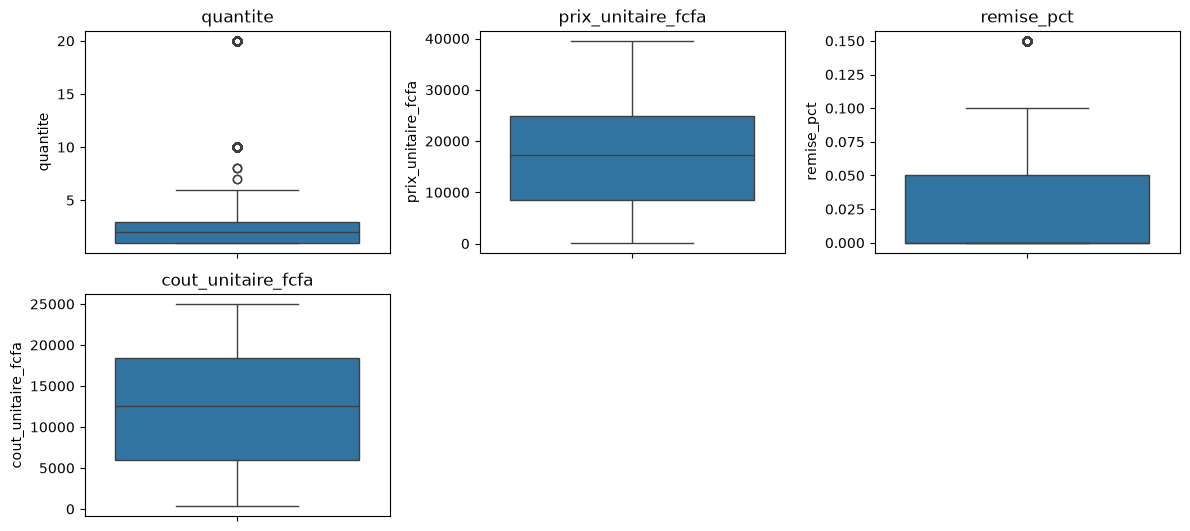

In [91]:
import matplotlib.pyplot as plt
import seaborn as sns

colonnes_numeriques = ventes.select_dtypes(include=["number"]).columns

plt.figure(figsize=(12, 8))
for i, col in enumerate(colonnes_numeriques, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(y=ventes[col])
    plt.title(col)

plt.tight_layout()
plt.show()

Nos outliers observes sont raisonnables sur le plan commercial.

Analyse descriptive apres traitement.

In [92]:
ventes.describe()

,date_vente,quantite,prix_unitaire_fcfa,remise_pct,cout_unitaire_fcfa
count,49901,50000.0,50000.000000,50000.000000,50000.000000
mean,2024-07-02 14:04:06.007094,2.5395,16992.623047,0.039841,12293.902344
min,2023-01-01 00:00:00,1.0,162.000000,0.000000,358.000000
25%,2023-10-04 00:00:00,1.0,8600.000000,0.000000,5962.000000
50%,2024-07-03 00:00:00,2.0,17200.000000,0.000000,12504.000000
75%,2025-04-04 00:00:00,3.0,24800.000000,0.050000,18460.000000
max,2025-12-30 00:00:00,20.0,39550.000000,0.150000,24979.000000
std,NaN,2.50664,9973.338867,0.053078,7081.837891


2.Table ACHATS

In [93]:
achats = pd.read_csv(os.path.join(dossier_brut, "ACHATS_BRUT.csv"))
achats.head(2)

,id_achat,date_commande,date_reception,id_fournisseur,id_produit,id_magasin,quantite_commandee,prix_achat_unitaire_fcfa,statut_achat
0,ACH000001,2025-11-06,2025-11-17,FOU079,PRD0327,MAG006,340,3075,Annulé
1,ACH000002,2025-12-03,2025-12-09,FOU018,PRD0492,MAG014,282,1018,Annulé


Variables flottantes

In [94]:
achats["prix_achat_unitaire_fcfa"] = pd.to_numeric(
    achats["prix_achat_unitaire_fcfa"], errors="coerce"
).astype("float")

Variables dates

In [95]:
columns_date = [
    "date_commande",
    "date_reception",
]

for col in columns_date:
    achats[col] = pd.to_datetime(
    achats[col], errors="coerce"
)
    


Suppression des doublons

In [96]:
achats.drop_duplicates(inplace=True)
achats.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   id_achat                  10000 non-null  str           
 1   date_commande             10000 non-null  datetime64[us]
 2   date_reception            9692 non-null   datetime64[us]
 3   id_fournisseur            10000 non-null  str           
 4   id_produit                10000 non-null  str           
 5   id_magasin                10000 non-null  str           
 6   quantite_commandee        10000 non-null  int64         
 7   prix_achat_unitaire_fcfa  10000 non-null  float64       
 8   statut_achat              10000 non-null  str           
dtypes: datetime64[us](2), float64(1), int64(1), str(5)
memory usage: 703.3 KB


C:\Users\Agatte_Nganzeu\AppData\Local\Temp\ipykernel_20180\2714758040.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  achats.drop_duplicates(inplace=True)


Observation des valeurs aberrantes.

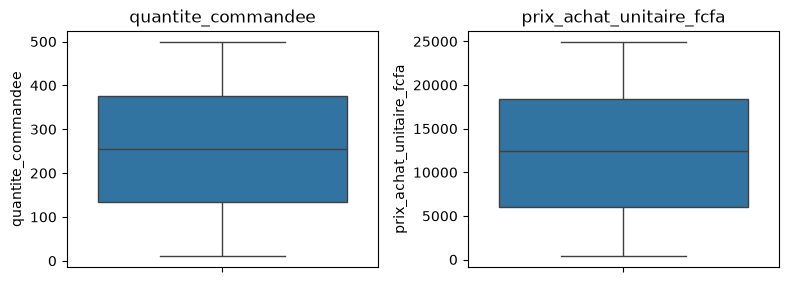

In [97]:
import matplotlib.pyplot as plt
import seaborn as sns

colonnes_numeriques = achats.select_dtypes(include=["number"]).columns

plt.figure(figsize=(12, 8))
for i, col in enumerate(colonnes_numeriques, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(y=achats[col])
    plt.title(col)

plt.tight_layout()
plt.show()

Analyse descriptive apres traitement.

In [98]:
achats.describe()

,date_commande,date_reception,quantite_commandee,prix_achat_unitaire_fcfa
count,10000,9692,10000.000000,10000.000000
mean,2024-07-02 07:09:07.200000,2024-07-19 22:07:13.842344,254.564200,12283.396000
min,2023-01-01 00:00:00,2023-01-04 00:00:00,10.000000,358.000000
25%,2023-09-28 00:00:00,2023-10-13 00:00:00,133.000000,5992.000000
50%,2024-07-06 00:00:00,2024-07-24 00:00:00,254.000000,12441.000000
75%,2025-04-02 00:00:00,2025-04-20 00:00:00,376.000000,18376.000000
max,2025-12-30 00:00:00,2026-01-30 00:00:00,500.000000,24979.000000
std,NaN,NaN,141.474778,7033.695136


3.Table CLIENTS

In [99]:
clients = pd.read_csv(os.path.join(dossier_brut, "CLIENTS_BRUT.csv"))
clients.head(2)

,id_client,nom_client,type_client,ville,region,date_inscription,sexe_contact,segment_initial,telephone,email
0,CLI00001,Client_00001,Revendeur,Bamenda,Nord-Ouest,2024-12-19,F,VIP,237697286856,client1@example.cm
1,CLI00002,Client_00002,Restaurant,Edéa,Littoral,2022-03-15,Non renseigné,Standard,237669741932,client2@example.cm


Variables en chaine de caractere / Normalisation de la colonne ville / remplacement des ville et email manquants par Inconnu.

In [100]:
clients["telephone"] = (clients["telephone"].astype(str).str.lower().str.strip())

clients["ville"] = (
    clients["ville"]
    .astype("string")
    .str.strip()
    .str.title()
)
mapping_ville = {
    'Yaounde': 'Yaoundé',
}
clients["ville"] = clients["ville"].replace(mapping_ville)

clients["ville"] = clients["ville"].replace(
    ["nan", "inconnu", "none", ""], np.nan
)

clients["ville"] = clients["ville"].fillna("Inconnue")
clients["email"] = clients["email"].fillna("Inconnue")

clients["ville"].unique()

<StringArray>
[   'Bamenda',       'Edéa',     'Douala', 'Ngaoundéré',  'Bafoussam',
       'Buea',     'Garoua',    'Ebolowa',     'Maroua',    'Bertoua',
    'Dschang',   'Inconnue',      'Kumba',      'Limbé',    'Yaoundé',
      'Kribi']
Length: 16, dtype: string

Variables dates

In [101]:
clients["date_inscription"] = pd.to_datetime(
    clients["date_inscription"], errors="coerce"
)

4.Table COMMERCIAUX

In [102]:
commerciaux = pd.read_csv(os.path.join(dossier_brut, "COMMERCIAUX_BRUT.csv"))
commerciaux.head(2)

,id_commercial,nom_commercial,ville_affectation,region_affectation,date_embauche,objectif_mensuel_fcfa,statut
0,COM001,Commercial 01,Maroua,Extrême-Nord,2025-01-13,4000000,Actif
1,COM002,Commercial 02,Ngaoundéré,Adamaoua,2025-03-20,6250000,Suspendu


Variables dates

In [103]:
commerciaux["date_embauche"] = pd.to_datetime(
    commerciaux["date_embauche"], errors="coerce"
)

Variables flottantes

In [104]:
commerciaux["objectif_mensuel_fcfa"] = pd.to_numeric(
    commerciaux["objectif_mensuel_fcfa"], errors="coerce"
).astype("float")

Observation des valeurs aberrantes.

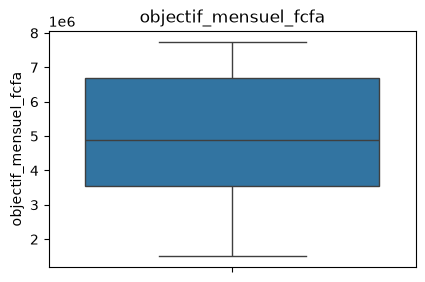

In [105]:
import matplotlib.pyplot as plt
import seaborn as sns

colonnes_numeriques = commerciaux.select_dtypes(include=["number"]).columns

plt.figure(figsize=(12, 8))
for i, col in enumerate(colonnes_numeriques, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(y=commerciaux[col])
    plt.title(col)

plt.tight_layout()
plt.show()

Analyse descriptive apres traitement.

In [106]:
commerciaux.describe()

,date_embauche,objectif_mensuel_fcfa
count,50,5.000000e+01
mean,2022-07-29 06:14:24,4.985000e+06
min,2019-01-01 00:00:00,1.500000e+06
25%,2021-02-06 00:00:00,3.562500e+06
50%,2022-09-30 12:00:00,4.875000e+06
75%,2024-02-14 18:00:00,6.687500e+06
max,2025-07-28 00:00:00,7.750000e+06
std,NaN,1.861540e+06


5.Table DEPENSES

In [107]:
depenses = pd.read_csv(os.path.join(dossier_brut, "DEPENSES_BRUT.csv"))
depenses.head(2)

,id_depense,date_depense,id_magasin,categorie_depense,description,montant_fcfa,mode_paiement,valide_par
0,DEP000001,2023-05-05,MAG012,Télécommunications,Facture mensuelle,275000,Espèces,Comptabilité
1,DEP000002,2023-05-01,MAG011,Électricité,Paiement prestataire,2155000,Espèces,Responsable magasin


Variables flottantes / les montants negatifs sont remplace par leur valeur absolu 

In [108]:
depenses["montant_fcfa"] = pd.to_numeric(
    depenses["montant_fcfa"], errors="coerce"
).astype("float64")

depenses.loc[
    depenses["montant_fcfa"] < 0,
    "montant_fcfa"
] = depenses.loc[
    depenses["montant_fcfa"] < 0,
    "montant_fcfa"
].abs()
depenses = depenses.iloc[:, :8].copy()

Variables dates

In [109]:
depenses["date_depense"] = pd.to_datetime(
    depenses["date_depense"], errors="coerce"
)

Remplacement des manquants dans valide_par; par Inconnu.

In [110]:
depenses["valide_par"] = depenses["valide_par"].fillna("Inconnu")

Suppression des doublons.

In [111]:
depenses.drop_duplicates(inplace=True)
depenses.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   id_depense         5000 non-null   str           
 1   date_depense       5000 non-null   datetime64[us]
 2   id_magasin         5000 non-null   str           
 3   categorie_depense  5000 non-null   str           
 4   description        5000 non-null   str           
 5   montant_fcfa       5000 non-null   float64       
 6   mode_paiement      5000 non-null   str           
 7   valide_par         5000 non-null   str           
dtypes: datetime64[us](1), float64(1), str(6)
memory usage: 312.6 KB


C:\Users\Agatte_Nganzeu\AppData\Local\Temp\ipykernel_20180\1348709227.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  depenses.drop_duplicates(inplace=True)


Observation des valeurs aberrantes.

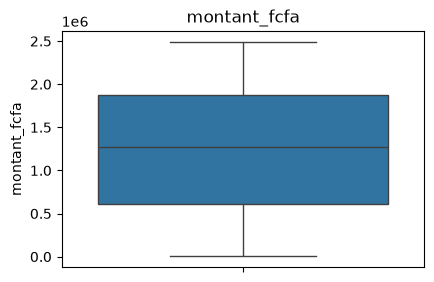

In [112]:
import matplotlib.pyplot as plt
import seaborn as sns

colonnes_numeriques = depenses.select_dtypes(include=["number"]).columns

plt.figure(figsize=(12, 8))
for i, col in enumerate(colonnes_numeriques, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(y=depenses[col])
    plt.title(col)

plt.tight_layout()
plt.show()

Analyse descriptive apres traitement.

In [113]:
depenses.describe()

,date_depense,montant_fcfa
count,5000,5.000000e+03
mean,2024-07-09 01:12:00,1.250051e+06
min,2023-01-01 00:00:00,3.062000e+03
25%,2023-09-30 00:00:00,6.150000e+05
50%,2024-07-09 00:00:00,1.270000e+06
75%,2025-04-18 06:00:00,1.880000e+06
max,2025-12-30 00:00:00,2.495000e+06
std,NaN,7.287544e+05


6.Table FOURNISSEURS

In [114]:
fournisseurs = pd.read_csv(os.path.join(dossier_brut, "FOURNISSEURS_BRUT.csv"))
fournisseurs.head(2)

,id_fournisseur,nom_fournisseur,ville,region,delai_contractuel_jours,type_fournisseur,telephone
0,FOU001,Fournisseur 001 SARL,Maroua,Extrême-Nord,11,International,237681157126
1,FOU002,Fournisseur 002 SARL,Douala,Littoral,5,Local,237652647076


Variable a chaine de caractere

In [115]:
fournisseurs["telephone"] = (clients["telephone"].astype(str).str.lower().str.strip())

Variables entieres

In [116]:
fournisseurs["delai_contractuel_jours"] = pd.to_numeric(
    fournisseurs["delai_contractuel_jours"], errors="coerce"
).astype("Int64")

Observation des valeurs aberrantes.

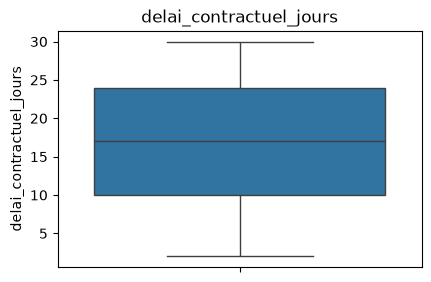

In [117]:
import matplotlib.pyplot as plt
import seaborn as sns

colonnes_numeriques = fournisseurs.select_dtypes(include=["number"]).columns

plt.figure(figsize=(12, 8))
for i, col in enumerate(colonnes_numeriques, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(y=fournisseurs[col])
    plt.title(col)

plt.tight_layout()
plt.show()

Analyse descriptive apres traitement.

In [118]:
fournisseurs.describe()

,delai_contractuel_jours
count,100.0
mean,16.96
std,8.419458
min,2.0
25%,10.0
50%,17.0
75%,24.0
max,30.0


7.Table LIVRAISONS

In [119]:
livraisons = pd.read_csv(os.path.join(dossier_brut, "LIVRAISONS_BRUT.csv"))
livraisons.head(2)

,id_livraison,date_commande,date_prevue,date_livraison,id_client,id_magasin,transporteur,cout_livraison_fcfa,statut_livraison
0,LIV000001,2023-12-17,2023-12-18,2023-12-18,CLI03698,MAG012,Prestataire A,41000,En cours
1,LIV000002,2023-06-27,2023-07-01,2023-07-01,CLI02764,MAG014,Moto express,15500,Échec


Variables flottantes

In [120]:
livraisons["cout_livraison_fcfa"] = pd.to_numeric(
    livraisons["cout_livraison_fcfa"], errors="coerce"
).astype("float64")

Variables dates 

In [121]:
columns_date = [
    "date_commande",
    "date_prevue",
    "date_livraison"
]

for col in columns_date:
    livraisons[col] = pd.to_datetime(
    livraisons[col], errors="coerce"
)

suppression des doublons.

In [122]:
livraisons.drop_duplicates(inplace=True)
livraisons.info()

<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   id_livraison         15000 non-null  str           
 1   date_commande        15000 non-null  datetime64[us]
 2   date_prevue          15000 non-null  datetime64[us]
 3   date_livraison       14775 non-null  datetime64[us]
 4   id_client            15000 non-null  str           
 5   id_magasin           15000 non-null  str           
 6   transporteur         15000 non-null  str           
 7   cout_livraison_fcfa  15000 non-null  float64       
 8   statut_livraison     15000 non-null  str           
dtypes: datetime64[us](3), float64(1), str(5)
memory usage: 1.0 MB


C:\Users\Agatte_Nganzeu\AppData\Local\Temp\ipykernel_20180\3067160353.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  livraisons.drop_duplicates(inplace=True)


Observation des valeurs aberrantes.

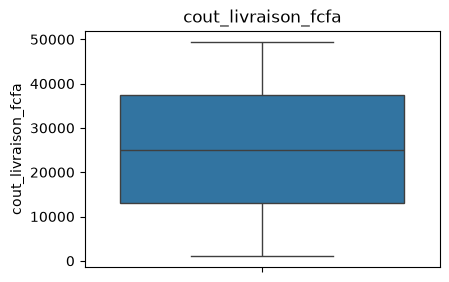

In [123]:
import matplotlib.pyplot as plt
import seaborn as sns

colonnes_numeriques = livraisons.select_dtypes(include=["number"]).columns

plt.figure(figsize=(12, 8))
for i, col in enumerate(colonnes_numeriques, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(y=livraisons[col])
    plt.title(col)

plt.tight_layout()
plt.show()

Analyse descriptive apres traitement.

In [124]:
livraisons.describe()

,date_commande,date_prevue,date_livraison,cout_livraison_fcfa
count,15000,15000,14775,15000.000000
mean,2024-06-30 11:31:12,2024-07-02 11:54:37.440000,2024-07-04 07:28:31.187817,25231.666667
min,2023-01-01 00:00:00,2023-01-01 00:00:00,2022-12-31 00:00:00,1000.000000
25%,2023-09-30 00:00:00,2023-10-02 00:00:00,2023-10-02 00:00:00,13000.000000
50%,2024-07-02 00:00:00,2024-07-03 12:00:00,2024-07-04 00:00:00,25000.000000
75%,2025-03-31 00:00:00,2025-04-02 00:00:00,2025-04-02 00:00:00,37500.000000
max,2025-12-30 00:00:00,2026-01-03 00:00:00,2030-12-31 00:00:00,49500.000000
std,NaN,NaN,NaN,14085.915830


8.Table MAGASINS

In [125]:
magasins = pd.read_csv(os.path.join(dossier_brut, "MAGASINS_BRUT.csv"))
magasins.head(2)

,id_magasin,nom_magasin,ville,region,date_ouverture,surface_m2
0,MAG001,Agence Douala,Douala,Littoral,2019-04-02,80
1,MAG002,Agence Yaoundé,Yaoundé,Centre,2021-01-31,120


Variables flottantes

In [126]:
magasins["surface_m2"] = pd.to_numeric(
    magasins["surface_m2"], errors="coerce"
).astype("float64")

Variables dates

In [127]:
magasins["date_ouverture"] = pd.to_datetime(
    magasins["date_ouverture"], errors="coerce"
)

Observation des valeurs aberrantes.

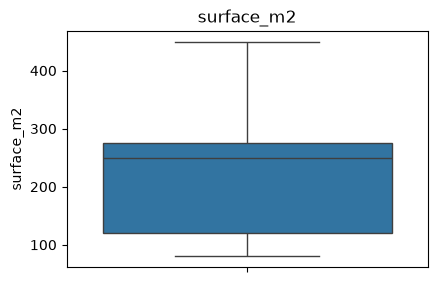

In [128]:
import matplotlib.pyplot as plt
import seaborn as sns

colonnes_numeriques = magasins.select_dtypes(include=["number"]).columns

plt.figure(figsize=(12, 8))
for i, col in enumerate(colonnes_numeriques, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(y=magasins[col])
    plt.title(col)

plt.tight_layout()
plt.show()

Analyse descriptive apres traitement.

In [129]:
magasins.describe()

,date_ouverture,surface_m2
count,15,15.000000
mean,2020-07-04 06:24:00,214.666667
min,2018-01-27 00:00:00,80.000000
25%,2019-01-23 12:00:00,120.000000
50%,2020-06-14 00:00:00,250.000000
75%,2021-11-29 12:00:00,275.000000
max,2023-09-01 00:00:00,450.000000
std,NaN,125.519871


9.Table PRODUITS

In [130]:
produits = pd.read_csv(os.path.join(dossier_brut, "PRODUITS_BRUT.csv"))
produits.head(2)

,id_produit,nom_produit,categorie,marque,cout_achat_unitaire,prix_vente_catalogue,unite,seuil_alerte,fournisseur_principal
0,PRD0001,Jus Classique 1,Produits alimentaires,FreshCo,23176,31150,sac,23,FOU012
1,PRD0002,Lait Plus 2,Hygiène,GlobalFoods,3469,4550,pièce,68,FOU069


Variables categorielle / Normalisation et remplacement des categories manquants par Inconnu.

In [131]:
produits["categorie"] = (
    produits["categorie"]
    .astype("string")
    .str.strip()
    .str.title()
)
mapping_cat = {
    'Alimentaire': 'Produits Alimentaires',
    'Hygiene': 'Hygiène',
    'Boissons': 'Boisson'
}
produits["categorie"] = produits["categorie"].replace(mapping_cat)

produits["categorie"] = produits["categorie"].replace(
    ["nan", "inconnu", "none", ""], np.nan
)

produits["categorie"] = produits["categorie"].fillna("Inconnue")

produits["categorie"].unique()

<StringArray>
['Produits Alimentaires',               'Hygiène',               'Boisson',
          'Électronique',             'Entretien',              'Épicerie',
              'Inconnue']
Length: 7, dtype: string

Variables flottantes

In [132]:
columns_float = [
    "cout_achat_unitaire",
    "prix_vente_catalogue",
]

for col in columns_float:
    produits[col] = pd.to_numeric(produits[col], errors="coerce", downcast="float")
    

Observation des valeurs aberrantes.

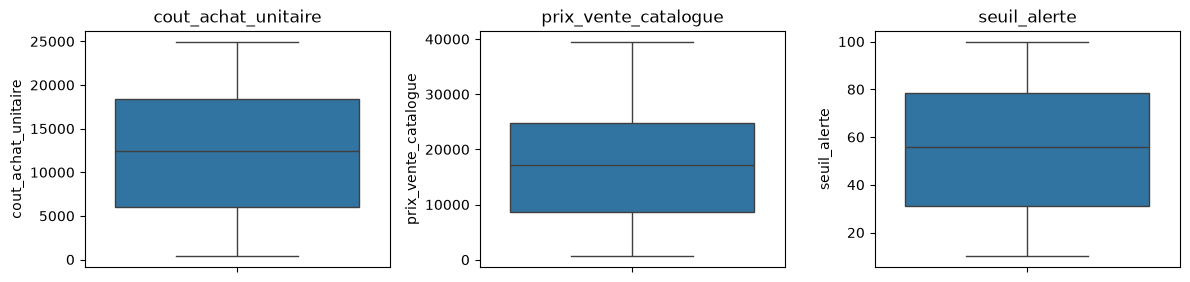

In [133]:
import matplotlib.pyplot as plt
import seaborn as sns

colonnes_numeriques = produits.select_dtypes(include=["number"]).columns

plt.figure(figsize=(12, 8))
for i, col in enumerate(colonnes_numeriques, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(y=produits[col])
    plt.title(col)

plt.tight_layout()
plt.show()

Analyse descriptive apres traitement.

In [134]:
produits.describe()

,cout_achat_unitaire,prix_vente_catalogue,seuil_alerte
count,500.000000,500.000000,500.000000
mean,12298.456055,17006.900391,55.156000
std,7080.373535,9970.562500,26.928311
min,358.000000,600.000000,10.000000
25%,5984.500000,8600.000000,31.000000
50%,12488.000000,17125.000000,56.000000
75%,18439.750000,24812.500000,78.250000
max,24979.000000,39550.000000,100.000000


10.Table STOCKS

In [135]:
stocks = pd.read_csv(os.path.join(dossier_brut, "STOCKS_BRUT.csv"))
stocks.head(2)

,id_mouvement,date_mouvement,id_produit,id_magasin,type_mouvement,quantite,motif,reference_document
0,MVT000001,2023-07-28,PRD0093,MAG006,Entrée,20,Transfert,DOC82981
1,MVT000002,2023-06-19,PRD0279,MAG004,Sortie,-69,Casse,DOC76413


Variables entieres / les quantites negatives qui sont de type different de Sortie sont remplacees par leur valeurs absolu.

In [136]:
stocks["quantite"] = pd.to_numeric(
    stocks["quantite"], errors="coerce"
).astype("Int64")

condition = (stocks["quantite"] < 0) & (stocks["type_mouvement"].isin(["Entrée", "Retour"]))
stocks.loc[condition, "quantite"] = stocks.loc[condition, "quantite"].abs()


Variables dates

In [137]:
stocks["date_mouvement"] = pd.to_datetime(
    stocks["date_mouvement"], errors="coerce"
)

Remplacement des motifs manquants par Inconnu

In [138]:
stocks["motif"] = stocks["motif"].fillna("Inconnu")

Suppression des doublons.

In [139]:
stocks.drop_duplicates(inplace=True)
stocks.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   id_mouvement        20000 non-null  str           
 1   date_mouvement      20000 non-null  datetime64[us]
 2   id_produit          20000 non-null  str           
 3   id_magasin          20000 non-null  str           
 4   type_mouvement      20000 non-null  str           
 5   quantite            20000 non-null  Int64         
 6   motif               20000 non-null  str           
 7   reference_document  20000 non-null  str           
dtypes: Int64(1), datetime64[us](1), str(6)
memory usage: 1.2 MB


C:\Users\Agatte_Nganzeu\AppData\Local\Temp\ipykernel_20180\2227816132.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  stocks.drop_duplicates(inplace=True)


Observation des valeurs aberrantes.

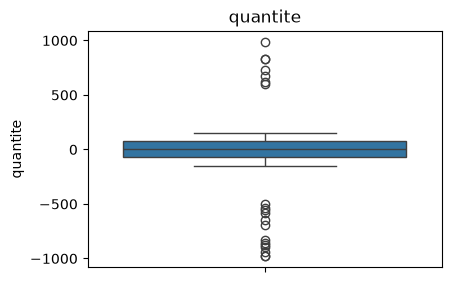

In [140]:
import matplotlib.pyplot as plt
import seaborn as sns

colonnes_numeriques = stocks.select_dtypes(include=["number"]).columns

plt.figure(figsize=(12, 8))
for i, col in enumerate(colonnes_numeriques, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(y=stocks[col])
    plt.title(col)

plt.tight_layout()
plt.show()

Nos outliers postifs sont raisonnable sur le plan commercial

Analyse descriptive apres traitement.

In [141]:
stocks.describe()

,date_mouvement,quantite
count,20000,20000.0
mean,2024-06-25 20:07:48,3.70105
min,2023-01-01 00:00:00,-981.0
25%,2023-09-26 00:00:00,-71.0
50%,2024-06-24 00:00:00,8.0
75%,2025-03-26 00:00:00,79.0
max,2025-12-30 00:00:00,990.0
std,NaN,90.101092


Verification du type de ces quantite negatives.

In [142]:
# Filtrer les lignes où la quantité est négative et afficher les types de mouvements uniques correspondants
types_mouvements_negatifs = stocks.loc[stocks["quantite"] < 0, "type_mouvement"].unique()

print("Types de mouvements associés aux quantités négatives :", types_mouvements_negatifs)

Types de mouvements associés aux quantités négatives : <StringArray>
['Sortie']
Length: 1, dtype: str


Nos outliers negatifs sont raisonnables car ils s'agit des Sortie en Stock.

### III.Traitement des cles orphelines.

### CLIENT

Vérifions si tous les clients présents dans ventes et livraisons existent dans la table clients.

In [143]:
# Récupérer les identifiants uniques
clients_ref = set(clients["id_client"].dropna())
clients_ventes = set(ventes["id_client"].dropna())
clients_livraisons = set(livraisons["id_client"].dropna())

# Vérifier les correspondances
resultat_ventes = clients_ventes.issubset(clients_ref)
resultat_livraisons = clients_livraisons.issubset(clients_ref)

print("Clients de VENTES présents dans CLIENTS :", resultat_ventes)
print("Clients de LIVRAISONS présents dans CLIENTS :", resultat_livraisons)

# Vérification globale
print("Toutes les références clients sont valides :",
      resultat_ventes and resultat_livraisons)

Clients de VENTES présents dans CLIENTS : False
Clients de LIVRAISONS présents dans CLIENTS : True
Toutes les références clients sont valides : False


Nombre de client present dans ventes et absent dans clients

In [144]:
nombre_clients_absents = ventes.loc[
    ~ventes["id_client"].isin(clients["id_client"]),
    "id_client"
].nunique()

print("Nombre de clients présents dans VENTES et absents de CLIENTS :",
      nombre_clients_absents)

Nombre de clients présents dans VENTES et absents de CLIENTS : 1


Creons un client fictif représentant le client non identifiés 

In [145]:
nouveau_client = pd.DataFrame([{
    "id_client": "CL_INCONNU",
    "nom_client": "Client inconnu",
    "type_client": "Inconnue",
    "ville": "Inconnue",
    "region": "Inconnue",
    "date_inscription": pd.NaT,
    "sexe_contact": "Non renseigné",
    "segment_initial": "Inconnue",
    "telephone": "Inconnue",
    "email": "Inconnue"
}])

clients = pd.concat(
    [clients, nouveau_client],
    ignore_index=True
)

Remplacons les identifiants du client absents de la table clients par CL_INCONNU

In [146]:
condition = ~ventes["id_client"].isin(clients["id_client"])

ventes.loc[condition, "id_client"] = "CL_INCONNU"

In [147]:
ventes.info()

<class 'pandas.DataFrame'>
Index: 50000 entries, 0 to 49999
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   id_vente            50000 non-null  str           
 1   date_vente          49901 non-null  datetime64[us]
 2   id_client           50000 non-null  str           
 3   id_produit          50000 non-null  str           
 4   id_magasin          50000 non-null  str           
 5   id_commercial       50000 non-null  str           
 6   quantite            50000 non-null  Int64         
 7   prix_unitaire_fcfa  50000 non-null  float32       
 8   remise_pct          50000 non-null  float32       
 9   cout_unitaire_fcfa  50000 non-null  float32       
 10  mode_paiement       50000 non-null  str           
 11  statut_vente        50000 non-null  string        
 12  canal_vente         50000 non-null  str           
dtypes: Int64(1), datetime64[us](1), float32(3), str(7), string(1)


### PRODUIT

Vérifions si tous les produits présents dans ventes, achats et stocks existent dans la table produits.

In [148]:
produits_ref = set(produits["id_produit"].dropna())

produits_ventes = set(ventes["id_produit"].dropna())
produits_achats = set(achats["id_produit"].dropna())
produits_stocks = set(stocks["id_produit"].dropna())

resultat_ventes = produits_ventes.issubset(produits_ref)
resultat_achats = produits_achats.issubset(produits_ref)
resultat_stocks = produits_stocks.issubset(produits_ref)

print("Produits de VENTES présents dans PRODUITS :", resultat_ventes)
print("Produits de ACHATS présents dans PRODUITS :", resultat_achats)
print("Produits de STOCKS présents dans PRODUITS :", resultat_stocks)

print(
    "Toutes les références produits sont valides :",
    resultat_ventes and resultat_achats and resultat_stocks
)

Produits de VENTES présents dans PRODUITS : False
Produits de ACHATS présents dans PRODUITS : True
Produits de STOCKS présents dans PRODUITS : True
Toutes les références produits sont valides : False


Nombre de produit present dans ventes et absent dans la table produits

In [149]:
nombre_produits_absents = ventes.loc[
    ~ventes["id_produit"].isin(produits["id_produit"]),
    "id_produit"
].nunique()

print("Nombre de produits absents de PRODUITS :", nombre_produits_absents)

Nombre de produits absents de PRODUITS : 1


Creons un produit fictif représentant le produit non identifiés 

In [150]:
nouveau_produit = pd.DataFrame([{
    "id_produit": "PR_INCONNU",
    "nom_produit": "Produit inconnu",
    "categorie": "Inconnue",
    "marque": "Inconnue",
    "cout_achat_unitaire": pd.NA,
    "prix_vente_catalogue": pd.NA,
    "unite": "Inconnue",
    "seuil_alerte": pd.NA,
    "fournisseur_principal": "Inconnue"
}])

if "PR_INCONNU" not in produits["id_produit"].values:
    produits = pd.concat(
        [produits, nouveau_produit],
        ignore_index=True
    )

Remplacons les identifiants du produit absents de la table produits par PR_INCONNU

In [151]:
# Identifier les produits absents
condition = ~ventes["id_produit"].isin(produits["id_produit"])

# Conserver les identifiants originaux pour la traçabilité
ventes.loc[condition, "id_produit_original"] = ventes.loc[
    condition, "id_produit"
]

# Remplacer les identifiants absents
ventes.loc[condition, "id_produit"] = "PR_INCONNU"
ventes = ventes.drop(columns=["id_produit_original"])

### MAGASIN

Vérifions si tous les magasins présents dans ventes, achats, depenses, livraisons et stocks existent dans la table magasins.

In [152]:
# Ensemble des identifiants de magasins de référence
magasins_ref = set(magasins["id_magasin"].dropna())

# Identifiants présents dans chaque table
magasins_ventes = set(ventes["id_magasin"].dropna())
magasins_achats = set(achats["id_magasin"].dropna())
magasins_depenses = set(depenses["id_magasin"].dropna())
magasins_livraisons = set(livraisons["id_magasin"].dropna())
magasins_stocks = set(stocks["id_magasin"].dropna())

# Vérification de l'intégrité référentielle
resultat_ventes = magasins_ventes.issubset(magasins_ref)
resultat_achats = magasins_achats.issubset(magasins_ref)
resultat_depenses = magasins_depenses.issubset(magasins_ref)
resultat_livraisons = magasins_livraisons.issubset(magasins_ref)
resultat_stocks = magasins_stocks.issubset(magasins_ref)

# Affichage des résultats
print("VENTES :", resultat_ventes)
print("ACHATS :", resultat_achats)
print("DEPENSES :", resultat_depenses)
print("LIVRAISONS :", resultat_livraisons)
print("STOCKS :", resultat_stocks)

print(
    "Toutes les références magasins sont valides :",
    all([
        resultat_ventes,
        resultat_achats,
        resultat_depenses,
        resultat_livraisons,
        resultat_stocks
    ])
)

VENTES : True
ACHATS : True
DEPENSES : True
LIVRAISONS : True
STOCKS : False
Toutes les références magasins sont valides : False


Nombre de magasin present dans stocks et absent dans la table magasins

In [153]:
nombre_magasins_absents = stocks.loc[
    ~stocks["id_magasin"].isin(magasins["id_magasin"]),
    "id_magasin"
].nunique()

print("Nombre de magasins absents de MAGASINS :", nombre_magasins_absents)

Nombre de magasins absents de MAGASINS : 1


Creons un magasin fictif représentant le magasin non identifiés

In [154]:
nouveau_magasin = pd.DataFrame([{
    "id_magasin": "MG_INCONNU",
    "nom_magasin": "Magasin inconnu",
    "ville": "Inconnue",
    "region": "Inconnue",
    "date_ouverture": pd.NaT,
    "surface_m2": pd.NA
}])

# Vérifier que le magasin fictif n'existe pas déjà
if "MG_INCONNU" not in magasins["id_magasin"].values:
    magasins = pd.concat(
        [magasins, nouveau_magasin],
        ignore_index=True
    )

Remplacons les identifiants du magasin absents de la table magasins par MG_INCONNU

In [155]:
# Identifier les magasins absents
condition = ~stocks["id_magasin"].isin(magasins["id_magasin"])

# Conserver les identifiants originaux pour la traçabilité
stocks.loc[condition, "id_magasin_original"] = stocks.loc[
    condition, "id_magasin"
]

# Remplacer les identifiants absents
stocks.loc[condition, "id_magasin"] = "MG_INCONNU"
stocks = stocks.drop(columns=["id_magasin_original"])

### COMMERCIAL

Vérifions si tous les commerciaux présents dans ventes existent dans la table commerciaux.

In [156]:
commerciaux_ref = set(commerciaux["id_commercial"].dropna())
commerciaux_ventes = set(ventes["id_commercial"].dropna())
resultat_ventes = commerciaux_ventes.issubset(commerciaux_ref)
print("commerciaux de VENTES présents dans COMMERCIAUX :", resultat_ventes)
print(
    "Toutes les références produits sont valides :",
    resultat_ventes 
)

commerciaux de VENTES présents dans COMMERCIAUX : True
Toutes les références produits sont valides : True


### FOURNISSEUR

Vérifions si tous les fournisseurs présents dans achats et produits existent dans la table fournisseurs.

In [157]:
fournisseurs_ref = set(fournisseurs["id_fournisseur"].dropna())

fournisseurs_achats = set(achats["id_fournisseur"].dropna())
fournisseurs_produits = set(produits["fournisseur_principal"].dropna())

resultat_achats = fournisseurs_achats.issubset(fournisseurs_ref)
resultat_produits = fournisseurs_produits.issubset(fournisseurs_ref)

print("fournisseurs de ACHATS présents dans FOURNISSEURS :", resultat_achats)
print("fournisseurs de PRODUITS présents dans FOURNISSEURS :", resultat_produits)

print(
    "Toutes les références produits sont valides :",
    resultat_achats and resultat_produits
)

fournisseurs de ACHATS présents dans FOURNISSEURS : False
fournisseurs de PRODUITS présents dans FOURNISSEURS : False
Toutes les références produits sont valides : False


Nombre de fournisseur presents dans la table achats et absents dans la table fournisseurs et Nombre de fournisseur presents dans la table produits et absents dans la table fournisseurs

In [158]:
# 1. Nombre de fournisseurs uniques présents dans ACHATS mais absents de FOURNISSEURS
nb_absents_achats = achats.loc[
    ~achats["id_fournisseur"].isin(fournisseurs["id_fournisseur"]),
    "id_fournisseur"
].nunique()

# 2. Nombre de fournisseurs uniques présents dans PRODUITS mais absents de FOURNISSEURS
nb_absents_produits = produits.loc[
    ~produits["fournisseur_principal"].isin(fournisseurs["id_fournisseur"]),
    "fournisseur_principal"
].nunique()

# Affichage des nombres
print("Nombre de fournisseurs présents dans ACHATS mais absents de FOURNISSEURS :", nb_absents_achats)
print("Nombre de fournisseurs présents dans PRODUITS mais absents de FOURNISSEURS :", nb_absents_produits)

Nombre de fournisseurs présents dans ACHATS mais absents de FOURNISSEURS : 1
Nombre de fournisseurs présents dans PRODUITS mais absents de FOURNISSEURS : 1


Comparaison des fournisseurs presents dans les deux tables (achats et produits) et absents dans la table fornisseurs.

In [159]:
# 1. Extraction des identifiants uniques absents pour chaque table
id_absents_achats = achats.loc[
    ~achats["id_fournisseur"].isin(fournisseurs["id_fournisseur"]),
    "id_fournisseur"
].dropna().unique()

id_absents_produits = produits.loc[
    ~produits["fournisseur_principal"].isin(fournisseurs["id_fournisseur"]),
    "fournisseur_principal"
].dropna().unique()

# 2. Comparaison : S'il y a exactement 1 élément dans chaque et qu'ils sont égaux
# (On transforme en set ou on compare directement les valeurs si on est sûr qu'il y en a une seule)
sont_identiques = set(id_absents_achats) == set(id_absents_produits)

print("S'agit-il du même fournisseur manquant dans les deux tables ?", sont_identiques)

S'agit-il du même fournisseur manquant dans les deux tables ? False


Creons deux fournisseurs fictifs représentant les fournisseurs non identifiés.

In [160]:
nouveaux_fournisseurs = pd.DataFrame([
    {
        "id_fournisseur": "FOU1_INCONNU",
        "nom_fournisseur": "Fournisseur Inconnu 1",
        "ville": "Inconnue",
        "region": "Inconnue",
        "delai_contractuel_jours": pd.NA,
        "type_fournisseur": "Inconnu",
        "telephone": "Inconnu"
    },
    {
        "id_fournisseur": "FOU2_INCONNU",
        "nom_fournisseur": "Fournisseur Inconnu 2",
        "ville": "Inconnue",
        "region": "Inconnue",
        "delai_contractuel_jours": pd.NA,
        "type_fournisseur": "Inconnu",
        "telephone": "Inconnu"
    }
])

fournisseurs = pd.concat([fournisseurs, nouveaux_fournisseurs], ignore_index=True)

Remplacons les identifiants des fournisseurs absents de la table fournisseurs par FOU1_INCONNU dans la table achats et par FOU2_INCONNU dans la table produits.

In [161]:
achats["id_fournisseur"] = achats["id_fournisseur"].mask(
    ~achats["id_fournisseur"].isin(fournisseurs["id_fournisseur"]),
    "FOU1_INCONNU"
)

produits["fournisseur_principal"] = produits["fournisseur_principal"].mask(
    ~produits["fournisseur_principal"].isin(fournisseurs["id_fournisseur"]),
    "FOU2_INCONNU"
)

### IV.Colonnes ajoutees.

In [162]:
# 1. S'assurer que les colonnes numériques sont au bon format
colonnes_num = ["quantite", "prix_unitaire_fcfa", "cout_unitaire_fcfa", "remise_pct"]
for col in colonnes_num:
    ventes[col] = pd.to_numeric(ventes[col], errors="coerce").fillna(0)

# 2. Calcul du Chiffre d'Affaires Net par ligne
# Formule : Quantité * Prix Unitaire * (1 - Remise)
ventes["chiffre_affaire_net"] = (
    ventes["quantite"] 
    * ventes["prix_unitaire_fcfa"] 
    * (1 - ventes["remise_pct"])
)

# 3. Calcul du Coût Total par ligne
ventes["cout_total_ligne"] = ventes["quantite"] * ventes["cout_unitaire_fcfa"]

# 4. Calcul de la Marge Brute par ligne
ventes["marge_brute_ligne"] = ventes["chiffre_affaire_net"] - ventes["cout_total_ligne"]

# 5. Extraction de la période (Année-Mois) pour les graphiques temporels
# (Assurez-vous que la colonne date est bien au format datetime)
ventes["date_vente"] = pd.to_datetime(ventes["date_vente"], errors="coerce")
ventes["annee_mois"] = ventes["date_vente"].dt.to_period("M").astype(str)

### V.Structure finale.

In [163]:

# Liste explicite de vos 10 tables du projet AFRICA DISTRIBUTION SARL
noms_tables = [
    "ventes", 
    "achats", 
    "clients", 
    "commerciaux", 
    "depenses", 
    "fournisseurs", 
    "livraisons", 
    "magasins", 
    "produits", 
    "stocks"
]

resume_tables = []

for nom in noms_tables:
    # On vérifie si la variable existe bien dans l'espace de travail
    if nom in globals() and isinstance(globals()[nom], pd.DataFrame):
        df = globals()[nom]
        resume_tables.append({
            "Nom de la table": nom,
            "Nombre de lignes": df.shape[0],
            "Nombre de colonnes": df.shape[1]
        })
    else:
        resume_tables.append({
            "Nom de la table": nom,
            "Nombre de lignes": "Non chargée / Introuvable",
            "Nombre de colonnes": "-"
        })

# Création du DataFrame récapitulatif
df_resume = pd.DataFrame(resume_tables)

# Affichage du tableau
display(df_resume)

,Nom de la table,Nombre de lignes,Nombre de colonnes
0,ventes,50000,17
1,achats,10000,9
2,clients,5001,10
3,commerciaux,50,7
4,depenses,5000,8
5,fournisseurs,102,7
6,livraisons,15000,9
7,magasins,16,6
8,produits,501,9
9,stocks,20000,8


### VI.Sauvegarge des fichiers nettoyes.

In [164]:
import pathlib


# Le dossier existe déjà, cette ligne vérifie simplement son existence sans rien écraser
output_dir = pathlib.Path("DATA_NETTOYEE")
output_dir.mkdir(parents=True, exist_ok=True)

# Dictionnaire regroupant vos 10 tables
tables_dict = {
    "ventes": ventes,
    "achats": achats,
    "clients": clients,
    "commerciaux": commerciaux,
    "depenses": depenses,
    "fournisseurs": fournisseurs,
    "livraisons": livraisons,
    "magasins": magasins,
    "produits": produits,
    "stocks": stocks,
}

# Sauvegarde au format CSV
for nom, df in tables_dict.items():
    if nom in globals() and isinstance(df, pd.DataFrame):
        file_path = output_dir / f"{nom}_nettoye.csv"
        df.to_csv(file_path, index=False, encoding="utf-8-sig")
        print(f"✅ Table '{nom}' sauvegardée -> {file_path}")
    else:
        print(f"⚠️ Attention : La table '{nom}' est introuvable en mémoire.")



✅ Table 'ventes' sauvegardée -> DATA_NETTOYEE\ventes_nettoye.csv
✅ Table 'achats' sauvegardée -> DATA_NETTOYEE\achats_nettoye.csv
✅ Table 'clients' sauvegardée -> DATA_NETTOYEE\clients_nettoye.csv
✅ Table 'commerciaux' sauvegardée -> DATA_NETTOYEE\commerciaux_nettoye.csv
✅ Table 'depenses' sauvegardée -> DATA_NETTOYEE\depenses_nettoye.csv
✅ Table 'fournisseurs' sauvegardée -> DATA_NETTOYEE\fournisseurs_nettoye.csv
✅ Table 'livraisons' sauvegardée -> DATA_NETTOYEE\livraisons_nettoye.csv
✅ Table 'magasins' sauvegardée -> DATA_NETTOYEE\magasins_nettoye.csv
✅ Table 'produits' sauvegardée -> DATA_NETTOYEE\produits_nettoye.csv
✅ Table 'stocks' sauvegardée -> DATA_NETTOYEE\stocks_nettoye.csv
